---
title: "Лабораторна робота 5. Інтерпретація та дослідження поясненності моделей машинного навчання"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: {.callout-note}
## Місце лабораторної роботи в курсі

Наскрізні результати: *Research Specification v0.1* (ЛР1), *Experiment Design v0.2* (ЛР2), *Validation & Evidence Audit v0.3* (ЛР3), *Structure Discovery & Validation v0.4* (ЛР4). Тепер досліджуємо не лише якість прогнозу чи структуру даних, а й *надійність пояснень поведінки моделі*. Підсумок -- *Explanation Audit v0.5*.
:::

## Мета роботи

Сформувати вміння обґрунтовано обирати глобальні й локальні методи пояснення моделей машинного навчання, перевіряти їхню стійкість, чутливість до залежностей між ознаками та локальну точність апроксимації, відокремлюючи пояснення прогнозу від причинного пояснення явища.

## Завдання роботи

1. Побудувати контрольований ML-експеримент із корельованими ознаками.
2. Оцінити якість навченої моделі на відкладеній вибірці.
3. Дослідити глобальну перестановочну важливість ознак.
4. Порівняти індивідуальну та групову перестановочну важливість корельованих ознак.
5. Побудувати графік часткової залежності (PDP) та індивідуальні криві ICE.
6. Побудувати локальне сурогатне пояснення й оцінити його fidelity.
7. Обчислити значення Шеплі для простого прикладу вручну та програмно.
8. Провести аудит стійкості пояснень і сформулювати допустиме наукове твердження.
9. Перенести протокол на власне дисертаційне дослідження.

## Теоретичні відомості

*Перестановочна важливість (permutation importance)* вимірює падіння заданої метрики після руйнування зв'язку однієї ознаки з цільовою змінною:

$$
I_j=S(f,D)-\mathbb{E}_{\pi_j}\left[S(f,D_{\pi_j})\right].
$$

*Часткова залежність (partial dependence, PDP)* характеризує середній прогноз за штучно зафіксованого значення ознаки:

$$
PD_j(z)=\mathbb{E}_{X_{-j}}\left[f(z,X_{-j})\right].
$$

*Локальна сурогатна модель (local surrogate)* апроксимує поведінку складної моделі поблизу об'єкта $x_0$:

$$
g_{x_0}^{*}=\arg\min_{g\in G}\left\{\mathcal{L}(f,g,\pi_{x_0})+\Omega(g)\right\}.
$$

*SHAP* розподіляє відхилення прогнозу від базового значення між ознаками за правилами значень Шеплі. Результати всіх цих процедур залежать від вибраного виходу моделі, фону, метрики й припущень [@rudin2019stop; @hastie2009elements].

*Принцип:* пояснення моделі $f$ -- не доказ причинного впливу ознаки на явище [@pearl2009causality].

### Методологічна схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("RQ і навчена<br/>модель") --> B("Метод<br/>пояснення")
 B --> C("Глобальне та<br/>локальне пояснення")
 C --> D("Fidelity та<br/>stability")
 D --> E("Аудит залежних<br/>ознак")
 E --> F("Explanation<br/>Audit v0.5")
```

# Частина I. Навчальний експеримент

## 1. Дослідницьке питання та протокол

*RQ:* Чи можна вважати стабільними та предметно обґрунтованими пояснення прогнозів моделі, якщо дві ознаки містять майже однакову інформацію?

Використовуємо синтетичні дані: відомий генератор дозволяє перевіряти *обмеження* пояснень. Водночас це не є доказом щодо реальної предметної області.

*Протокол:* фіксуємо seed, навчальну/тестову вибірки, ROC AUC, вихід моделі (імовірність позитивного класу), спосіб перестановки, параметри локального оточення. Тестові дані не використовуємо для добору гіперпараметрів моделі.

## 2. Дані та базова модель


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score, r2_score
from sklearn.linear_model import Ridge

SEED = 42
rng = np.random.default_rng(SEED)
n = 1400
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.12, size=n)  # Корельована копія
x3 = rng.normal(size=n)
x4 = rng.normal(size=n)
logit = 1.8*x1 + 0.9*x3 - 0.7*x4
p = 1 / (1 + np.exp(-logit))
y = rng.binomial(1, p)
X = pd.DataFrame({
    'signal': x1, 'correlated_copy': x2,
    'secondary': x3, 'negative': x4
})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
model = RandomForestClassifier(
    n_estimators=100, min_samples_leaf=8,
    random_state=SEED, n_jobs=1
)
model.fit(X_train, y_train)
auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print('ROC AUC (test):', round(auc, 3))
display(X_train.corr().round(3))


ROC AUC (test): 0.85


,signal,correlated_copy,secondary,negative
signal,1.000,0.992,-0.008,0.066
correlated_copy,0.992,1.000,-0.011,0.062
secondary,-0.008,-0.011,1.000,0.003
negative,0.066,0.062,0.003,1.000


### Завдання 2.1

Визначте, чому кореляція `signal` і `correlated_copy` ускладнює приписування внеску кожній із цих ознак. Розрізніть: *відомий механізм генератора*, *навчену модель* і *пояснення моделі*.

## 3. Глобальна перестановочна важливість

Обчислимо середнє падіння ROC AUC після незалежних перестановок кожної ознаки. Це *модельно-залежна* оцінка на тестовій вибірці, а не причинний ефект.


,feature,mean_drop_auc,sd
1,correlated_copy,0.0841,0.0135
0,signal,0.0624,0.0069
2,secondary,0.0502,0.0062
3,negative,0.0266,0.0070


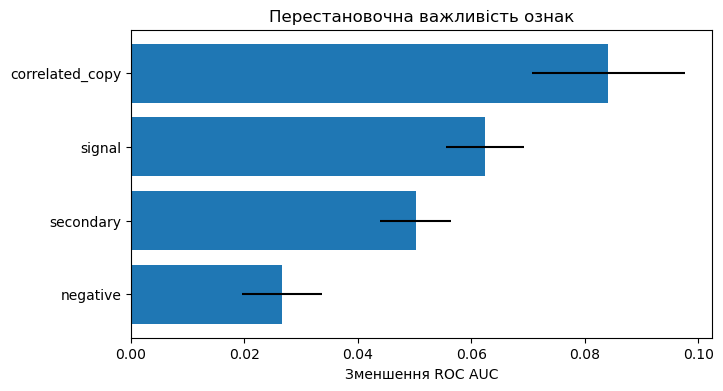

In [2]:
result = permutation_importance(
    model, X_test, y_test,
    scoring='roc_auc', n_repeats=10,
    random_state=SEED, n_jobs=1
)
importance = pd.DataFrame({
    'feature': X.columns,
    'mean_drop_auc': result.importances_mean,
    'sd': result.importances_std
}).sort_values('mean_drop_auc', ascending=False)
display(importance.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(importance['feature'], importance['mean_drop_auc'],
        xerr=importance['sd'])
ax.invert_yaxis()
ax.set(xlabel='Зменшення ROC AUC',
       title='Перестановочна важливість ознак')
plt.show()


### Завдання 3.1

Чи можна інтерпретувати малу індивідуальну важливість `signal` або `correlated_copy` як відсутність корисної інформації в ознаці? Аргументуйте.

## 4. Групова перестановка залежних ознак

Щоб дослідити *спільний* внесок корельованої пари, переставимо *однією і тією самою перестановкою рядків* обидві ознаки. Так зберігається їхній взаємний зв'язок, але руйнується відповідність із цільовою змінною. Ця процедура теж має припущення і не дорівнює причинному втручанню.


In [3]:
baseline_auc = roc_auc_score(
    y_test, model.predict_proba(X_test)[:, 1]
)
rng_group = np.random.default_rng(SEED + 1)
losses = []
for _ in range(30):
    X_perm = X_test.copy()
    idx = rng_group.permutation(len(X_perm))
    pair = X_perm[['signal', 'correlated_copy']].to_numpy().copy()
    X_perm.loc[:, ['signal', 'correlated_copy']] = pair[idx]
    auc_perm = roc_auc_score(
        y_test, model.predict_proba(X_perm)[:, 1]
    )
    losses.append(baseline_auc - auc_perm)
print('Групове падіння ROC AUC:', round(np.mean(losses), 4))
print('SD між перестановками:', round(np.std(losses, ddof=1), 4))
print('Сума індивідуальних важливостей пари:', round(
    importance.set_index('feature').loc[
        ['signal', 'correlated_copy'], 'mean_drop_auc'
    ].sum(), 4
))


Групове падіння ROC AUC: 0.2807
SD між перестановками: 0.0276
Сума індивідуальних важливостей пари: 0.1465


### Завдання 4.1

Порівняйте групову та індивідуальні важливості. Поясніть, чому вони не зобов'язані бути адитивними.

## 5. PDP та ICE

Побудуємо криві для `signal`. Пам'ятайте: коли ми змінюємо лише `signal`, залишаючи `correlated_copy` незмінною, можуть утворюватися малоймовірні комбінації ознак.


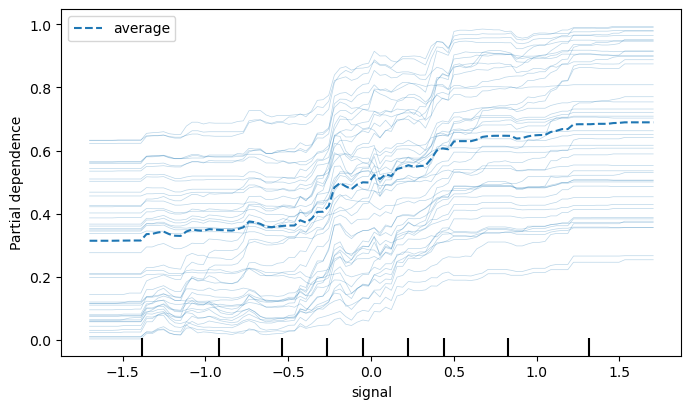

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
PartialDependenceDisplay.from_estimator(
    model, X_test, ['signal'], kind='both',
    subsample=45, random_state=SEED, ax=ax
)
plt.show()


### Завдання 5.1

Поясніть, що показує середня крива PDP і що -- окремі ICE-криві. Чому навіть гладка й монотонна PDP не доводить причинного впливу?

## 6. Локальне пояснення та fidelity

Побудуємо навчальний аналог ідеї LIME *без додаткової бібліотеки*. Виберемо один тестовий об'єкт, згенеруємо точки поблизу нього, обчислимо прогнози початкової моделі, навчимо зважений лінійний сурогат та перевіримо локальну якість апроксимації на *окремих* збурених точках.

У цьому спрощеному експерименті незалежні збурення можуть порушувати кореляцію ознак. Саме це потрібно зафіксувати як обмеження методу.

Для локальних ваг використаємо:

$$
w_i=\exp\left(-\frac{\|z_i-x_0\|_2^2}{2h^2}\right).
$$

Локальну fidelity оцінюємо за $R^2$ між прогнозами складної моделі та сурогату на контрольних збуреннях; це *не* якість прогнозування істинних міток.


In [5]:
x0 = X_test.iloc[0].to_numpy()
scales = X_train.std().to_numpy()
h = 0.8  # Ширина ядра в стандартизованому просторі
rng_local = np.random.default_rng(SEED + 2)

def perturb(m):
    return x0 + rng_local.normal(size=(m, len(x0))) * scales * 0.35

Z_fit = perturb(800)
Z_eval = perturb(250)

def model_prob(z):
    frame = pd.DataFrame(z, columns=X.columns)
    return model.predict_proba(frame)[:, 1]

def weights(z):
    standardized_distance2 = np.sum(((z - x0) / scales)**2, axis=1)
    return np.exp(-standardized_distance2 / (2 * h*h))

surrogate = Ridge(alpha=0.5)
surrogate.fit((Z_fit - x0) / scales,
              model_prob(Z_fit), sample_weight=weights(Z_fit))
actual = model_prob(Z_eval)
approx = surrogate.predict((Z_eval - x0) / scales)
fidelity = r2_score(actual, approx, sample_weight=weights(Z_eval))
print('Локальна fidelity (weighted R²):', round(fidelity, 3))
print('Прогноз моделі для x0:', round(model_prob(x0[None, :])[0], 3))
print('Прогноз сурогату для x0:', round(surrogate.predict(
    np.zeros((1, len(x0))))[0], 3))
display(pd.Series(surrogate.coef_, index=X.columns,
                  name='Локальний коефіцієнт').round(3))


Локальна fidelity (weighted R²): 0.039
Прогноз моделі для x0: 0.005
Прогноз сурогату для x0: 0.009


signal             0.002
correlated_copy    0.002
secondary          0.001
negative           0.003
Name: Локальний коефіцієнт, dtype: float64

### Завдання 6.1

Чи достатньо високої локальної fidelity, щоб визнати пояснення достовірним? Як зміняться результати за іншого $h$? Чому коефіцієнти сурогату не можна безпосередньо трактувати як причинні ефекти?

## 7. SHAP: контрольований приклад

Для двох ознак за заданою функцією коаліції:

$$
\phi_1=\frac12\left[v(\{1\})-v(\varnothing)\right]
+\frac12\left[v(\{1,2\})-v(\{2\})\right],
$$

$$
\phi_2=\frac12\left[v(\{2\})-v(\varnothing)\right]
+\frac12\left[v(\{1,2\})-v(\{1\})\right].
$$

Нехай $v(\varnothing)=0.20$, $v(\{1\})=0.50$, $v(\{2\})=0.30$, $v(\{1,2\})=0.70$.

*Вручну* обчисліть $\phi_1$, $\phi_2$ і перевірте властивість ефективності:

$$
v(\varnothing)+\phi_1+\phi_2=v(\{1,2\}).
$$


In [6]:
v_empty, v_1, v_2, v_12 = 0.20, 0.50, 0.30, 0.70
phi1 = 0.5*(v_1 - v_empty) + 0.5*(v_12 - v_2)
phi2 = 0.5*(v_2 - v_empty) + 0.5*(v_12 - v_1)
print('phi1:', round(phi1, 3), 'phi2:', round(phi2, 3))
print('Відновлений прогноз:', round(v_empty + phi1 + phi2, 3))
assert np.isclose(v_empty + phi1 + phi2, v_12)


phi1: 0.35 phi2: 0.15
Відновлений прогноз: 0.7


::: {.callout-important}
## Методологічна межа

У цьому прикладі *функція коаліції задана вручну*. Ми не обчислювали SHAP-значення для навченої RandomForest. Застосування бібліотеки SHAP до реальної моделі потребує окремо зафіксованих типу виходу, фонової вибірки та способу врахування залежностей між ознаками.
:::

## 8. Аудит стійкості пояснення

Повторимо перестановочну важливість за різних seed. Модель і тестова вибірка залишаються незмінними: отже, досліджується *стохастична варіативність процедури пояснення*, а не стабільність навчання моделі.


In [7]:
runs = []
for seed in range(8):
    r = permutation_importance(
        model, X_test, y_test,
        scoring='roc_auc', n_repeats=5,
        random_state=seed, n_jobs=1
    )
    runs.append(r.importances_mean)
runs = np.asarray(runs)
audit = pd.DataFrame({
    'feature': X.columns,
    'mean': runs.mean(axis=0),
    'sd_between_runs': runs.std(axis=0, ddof=1),
    'min': runs.min(axis=0),
    'max': runs.max(axis=0)
}).sort_values('mean', ascending=False)
display(audit.round(4))


,feature,mean,sd_between_runs,min,max
1,correlated_copy,0.0847,0.0069,0.0774,0.0987
0,signal,0.0614,0.0048,0.0539,0.0703
2,secondary,0.0491,0.0032,0.0442,0.0538
3,negative,0.0281,0.0038,0.0215,0.0339


## 9. Матриця загроз валідності пояснення

| Загроза | Механізм | Перевірка у ЛР5 | Межа висновку |
|---|---|---|---|
| Кореляція ознак | Розподіл прогностичної інформації | Індивідуальна/групова permutation importance | |
| Нереалістичні комбінації | Порушення спільного розподілу | Аналіз PDP та локальних збурень | |
| Локальна неточність | Сурогат погано апроксимує $f$ | Weighted $R^2$ на контрольних збуреннях | |
| Випадковість пояснення | Різні перестановки дають різні оцінки | Повторення за різних seed | |
| Невизначений фон | Різні правила атрибуції | Опис функції коаліції SHAP | |
| Причинна інтерпретація | Підміна пояснення моделі поясненням явища | Аудит формулювань | |

### Завдання 9.1

Для кожного рядка сформулюйте конкретне обмеження наукового твердження. Відокремте те, що *перевірено обчисленнями*, від того, що лише *потребує перевірки*.

# Частина II. Перенесення на дисертаційне дослідження

## 10. Об'єкт пояснення та дослідницьке питання

Візьміть модель із власного *Experiment Design v0.2* або структуру з *Structure Discovery & Validation v0.4*. Визначте: пояснюється окремий прогноз, група прогнозів чи поведінка моделі в цілому? Яка практична або наукова потреба в такому поясненні?

Якщо дисертаційна задача не є класифікацією, адаптуйте метрику й вихід моделі до свого типу задачі. Не копіюйте ROC AUC механічно.

## 11. Вибір методу та припущень

Заповніть таблицю:

| Компонент | Прийняте рішення | Обґрунтування |
|---|---|---|
| Дослідницьке питання | | |
| Модель і версія | | |
| Вихід моделі | | |
| Глобальне пояснення | | |
| Локальне пояснення (за потреби) | | |
| Референсний розподіл / фон | | |
| Залежності між ознаками | | |
| Критерій fidelity | | |
| Перевірка stability | | |
| Межі висновку | | |

## 12. Мінімальний XAI-експеримент

Виконайте *принаймні один* метод пояснення, що відповідає Вашому RQ, і *принаймні одну* перевірку надійності. Для локального сурогату -- оцініть fidelity; для глобального ранжування -- перевірте стійкість; за корельованих ознак -- дослідіть вплив їхньої залежності.

Не потрібно застосовувати всі методи до будь-якої дисертації. Важливіше методологічно коректно відповісти на конкретне питання.

## 13. Аудит наукового твердження

Побудуйте два формулювання:

1. *Неприпустиме надмірне твердження*, наприклад: «Ознака $X$ є причиною явища $Y$, оскільки має найбільший SHAP».
2. *Коректне обмежене твердження*: «За зафіксованої моделі, вибірки, виходу й способу пояснення ознака $X$ мала такий-то внесок у прогноз; його стабільність перевірено таким-то способом».

Поясніть, яких даних або припущень бракує для причинного висновку [@pearl2009causality; @hernan2020causal].

## 14. Підсумковий артефакт -- Explanation Audit v0.5

Підготуйте стислий документ (таблиці, графіки, код і текстові висновки):

1. RQ та об'єкт пояснення.
2. Версія моделі, дані, метрика та вихід.
3. Метод пояснення й параметри.
4. Основні результати з візуалізаціями.
5. Перевірка fidelity/stability/sensitivity відповідно до RQ.
6. Аналіз кореляцій, фону й інших загроз.
7. Допустиме наукове твердження та обмеження.
8. Відтворюваний протокол і зафіксовані рішення.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Specification<br/>v0.1") --> B("Experiment<br/>v0.2")
 B --> C("Evidence Audit<br/>v0.3")
 C --> D("Structure<br/>v0.4")
 D --> E("Explanation<br/>Audit v0.5")
```

# Контрольні питання

1. Що саме пояснює permutation importance?
2. Чому корельовані ознаки можуть мати малу індивідуальну важливість?
3. Чим групова перестановка відрізняється від індивідуальної?
4. Які припущення використовує PDP?
5. Що показують ICE-криві?
6. Яка ідея локальної сурогатної моделі?
7. Чим fidelity відрізняється від predictive performance?
8. Чому локальна fidelity залежить від вибору околу?
9. Як вручну обчислити значення Шеплі для двох ознак?
10. Чому функція коаліції впливає на SHAP-атрибуції?
11. Які види стабільності пояснення можна перевіряти?
12. Чому XAI не ідентифікує причинний ефект?
13. Як сформулювати коректне наукове твердження за результатами XAI?

# Вимоги до звіту

Звіт містить виконаний навчальний експеримент, таблиці й графіки пояснень, порівняння індивідуальної та групової важливості, оцінку локальної fidelity, аудит стійкості та власний *Explanation Audit v0.5*. Результати мають супроводжуватися змістовною інтерпретацією, а не лише кодом.

# Висновки

XAI є інструментом дослідження поведінки моделей, а не автоматичним механізмом відкриття причин. Надійність пояснення потребує експериментальної перевірки та явного опису припущень. Наступний крок -- формалізація причинного питання у ЛР6.

# Література та ресурси

Основні джерела: [@rudin2019stop; @hastie2009elements; @breiman2001two; @pearl2009causality; @hernan2020causal].

Додатково: [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html), [PDP та ICE](https://scikit-learn.org/stable/modules/partial_dependence.html), [SHAP](https://shap.readthedocs.io/).

::: {#refs}
:::
